# Goal-row vs format-row ablation

Does the search-aligned output depend on the goal sentence's tokens reading the image?

Two ablations of the search prompt, run with the same prompts, sampler and image sets as the
reference cells (HF causal hook; `inference/` for the reference runs):

- **goal-blind** — the tokens of the goal sentence (*"You are searching for a {target} in this image …"*) cannot attend to the image tokens at any layer.
- **format-blind** — the size-matched control: the tokens of the answer-format sentence cannot attend to the image tokens.

Reference cells are the intact search-prompt run and the free-view-prompt run from notebook 01.
Each run is scored per image with three metrics: Pearson CC of the model's density map with the human
search map (`cc_search`), with the human free-view map (`cc_free`), and with the model's own
free-view-prompt map (`vs free-view output`). The goal − format contrast is a paired per-image test.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg
from scipy import stats

# analysis/ is the parent of notebooks/
ANALYSIS = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ANALYSIS))
from helpers import runs as R, util as U
from helpers.util import gm  # repo-root gaze_metrics
print("data dir:", R.DATA_DIR)
MODELS = ["qwen-instruct", "gemma"]
CONDITIONS = ["tp", "ta"]
RUN_ORDER = ["intact", "format-blind", "goal-blind", "free-view"]

data dir: /Users/hanzh/Documents/Github/VLM-gaze/analysis/data


## Runs

In [3]:
# The four runs scored per model and condition: two reference cells (notebook 01) and two ablations.
rows = []
for model in MODELS:
    for condition in CONDITIONS:
        rows += [
            {"model": model, "condition": condition, "run": "intact", "ids": U.get_run_ids(model, condition, "search")},
            {"model": model, "condition": condition, "run": "format-blind", "ids": U.get_ablation_run_ids(model, condition, "format")},
            {"model": model, "condition": condition, "run": "goal-blind", "ids": U.get_ablation_run_ids(model, condition, "goal")},
            {"model": model, "condition": condition, "run": "free-view", "ids": U.get_run_ids(model, condition, "free")},
        ]
pd.DataFrame(rows)

,model,condition,run,ids
0,qwen-instruct,tp,intact,"[63889206, 63889207]"
1,qwen-instruct,tp,format-blind,"[63953880, 63998068]"
2,qwen-instruct,tp,goal-blind,"[63953881, 63998069]"
3,qwen-instruct,tp,free-view,"[63889208, 63889209]"
4,qwen-instruct,ta,intact,"[63889202, 63889203]"
5,qwen-instruct,ta,format-blind,"[63953876, 63998066]"
6,qwen-instruct,ta,goal-blind,"[63953877, 63998067]"
7,qwen-instruct,ta,free-view,"[63889204, 63889205]"
8,gemma,tp,intact,"[64991404, 58387155]"
9,gemma,tp,format-blind,"[64279304, 64348378, 64348381]"


## Per-image scores

In [4]:
def score_cell(model, condition):
    """Per-image cc_search / cc_free / CC-with-free-view-output for the four runs of one cell."""
    ids = {
        "intact": U.get_run_ids(model, condition, "search"),
        "format-blind": U.get_ablation_run_ids(model, condition, "format"),
        "goal-blind": U.get_ablation_run_ids(model, condition, "goal"),
        "free-view": U.get_run_ids(model, condition, "free"),
    }
    maps = {run: U.density_maps_from_points(U.load_fixations(run_ids, mode="vlm"), mode="vlm")
            for run, run_ids in ids.items()}
    human = U.load_fixations(ids["intact"], mode="human")
    human_search = U.density_maps_from_points(human, mode="human", goal="search")
    human_free = U.density_maps_from_points(human, mode="human", goal="free")

    # images present in every run and in both human maps
    keys = sorted(set.intersection(*[set(m) for m in maps.values()]) & set(human_search) & set(human_free))
    records = []
    for key in keys:
        for run in RUN_ORDER:
            m = maps[run][key]
            records.append({
                "model": model, "condition": condition, "run": run, "task": key[0], "name": key[1],
                "cc_search": gm.cc(m, human_search[key]),
                "cc_free": gm.cc(m, human_free[key]),
                "vs_freeview": np.nan if run == "free-view" else gm.cc(m, maps["free-view"][key]),
            })
    print(f"{model} {condition}: {len(keys)} images")
    return pd.DataFrame(records)


scores = pd.concat([score_cell(model, condition) for model in MODELS for condition in CONDITIONS],
                   ignore_index=True)
scores.head()

qwen-instruct tp: 2474 images


qwen-instruct ta: 2413 images


gemma tp: 2474 images


gemma ta: 2329 images


,model,condition,run,task,name,cc_search,cc_free,vs_freeview
0,qwen-instruct,tp,intact,bottle,000000001455.jpg,0.949018,0.079202,0.413516
1,qwen-instruct,tp,format-blind,bottle,000000001455.jpg,0.950752,0.080579,0.412692
2,qwen-instruct,tp,goal-blind,bottle,000000001455.jpg,0.461149,0.315120,0.698255
3,qwen-instruct,tp,free-view,bottle,000000001455.jpg,0.466493,0.607535,NaN
4,qwen-instruct,tp,intact,bottle,000000009527.jpg,0.867259,0.339115,0.115557


## Cell means

In [5]:
METRICS = ["cc_search", "cc_free", "vs_freeview"]

cell_means = (
    scores.groupby(["model", "condition", "run"], sort=False)[METRICS]
    .mean()
    .join(scores.groupby(["model", "condition", "run"], sort=False).size().rename("n"))
    .reset_index()
)
cell_means["run"] = pd.Categorical(cell_means["run"], RUN_ORDER)
cell_means.sort_values(["model", "condition", "run"]).round(3)

,model,condition,run,cc_search,cc_free,vs_freeview,n
12,gemma,ta,intact,0.401,0.226,0.280,2329
13,gemma,ta,format-blind,0.395,0.233,0.278,2329
14,gemma,ta,goal-blind,0.382,0.355,0.467,2329
15,gemma,ta,free-view,0.269,0.417,NaN,2329
8,gemma,tp,intact,0.703,0.165,0.363,2474
9,gemma,tp,format-blind,0.703,0.166,0.361,2474
10,gemma,tp,goal-blind,0.457,0.358,0.557,2474
11,gemma,tp,free-view,0.307,0.426,NaN,2474
4,qwen-instruct,ta,intact,0.463,0.234,0.287,2413
5,qwen-instruct,ta,format-blind,0.475,0.255,0.293,2413


## Goal-blind − format-blind, paired per image

`cohen_dz` is the paired effect size: mean of the per-image differences over their SD.

In [6]:
contrast_rows = []
for (model, condition), cell in scores.groupby(["model", "condition"], sort=False):
    wide = cell.pivot(index=["task", "name"], columns="run")
    for metric in METRICS:
        diff = (wide[(metric, "goal-blind")] - wide[(metric, "format-blind")]).dropna()
        test = pg.ttest(wide.loc[diff.index, (metric, "goal-blind")],
                        wide.loc[diff.index, (metric, "format-blind")], paired=True)
        ci = stats.t.ppf(0.975, len(diff) - 1) * diff.std(ddof=1) / np.sqrt(len(diff))
        contrast_rows.append({
            "model": model, "condition": condition, "metric": metric, "n": len(diff),
            "mean_diff": diff.mean(), "ci95_low": diff.mean() - ci, "ci95_high": diff.mean() + ci,
            "T": test["T"].iloc[0], "dof": test["dof"].iloc[0], "p_unc": test["p_val"].iloc[0],
            "cohen_dz": diff.mean() / diff.std(ddof=1),   # paired d: mean / SD of the per-image differences
        })

contrasts = pd.DataFrame(contrast_rows)
contrasts.round(3)

,model,condition,metric,n,mean_diff,ci95_low,ci95_high,T,dof,p_unc,cohen_dz
0,qwen-instruct,tp,cc_search,2474,-0.314,-0.323,-0.305,-71.128,2473,0.000,-1.430
1,qwen-instruct,tp,cc_free,2474,0.251,0.242,0.260,55.372,2473,0.000,1.113
2,qwen-instruct,tp,vs_freeview,2474,0.279,0.269,0.289,54.235,2473,0.000,1.090
3,qwen-instruct,ta,cc_search,2413,-0.067,-0.076,-0.058,-14.954,2412,0.000,-0.304
4,qwen-instruct,ta,cc_free,2413,0.159,0.150,0.168,33.486,2412,0.000,0.682
5,qwen-instruct,ta,vs_freeview,2413,0.295,0.284,0.305,55.483,2412,0.000,1.129
6,gemma,tp,cc_search,2474,-0.246,-0.256,-0.236,-48.998,2473,0.000,-0.985
7,gemma,tp,cc_free,2474,0.192,0.184,0.201,42.248,2473,0.000,0.849
8,gemma,tp,vs_freeview,2474,0.196,0.187,0.206,40.737,2473,0.000,0.819
9,gemma,ta,cc_search,2329,-0.013,-0.021,-0.005,-3.027,2328,0.002,-0.063


## Figure

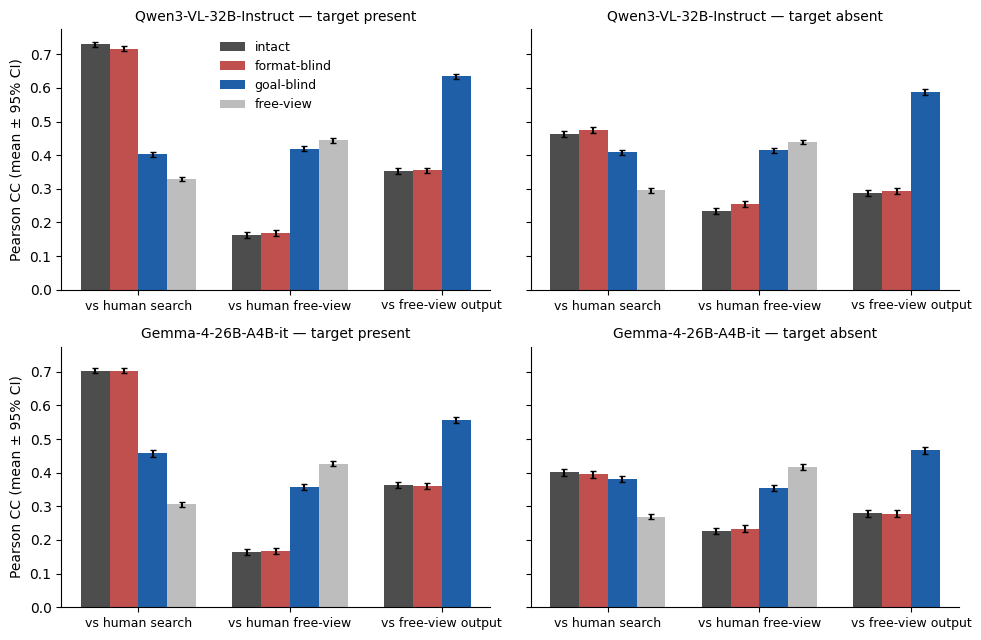

In [7]:
METRIC_LABELS = {"cc_search": "vs human search", "cc_free": "vs human free-view", "vs_freeview": "vs free-view output"}
RUN_COLORS = {"intact": "#4d4d4d", "format-blind": "#c0504d", "goal-blind": "#1f5fa8", "free-view": "#bdbdbd"}
CONDITION_LABELS = {"tp": "target present", "ta": "target absent"}

fig, axes = plt.subplots(len(MODELS), len(CONDITIONS), figsize=(10, 6.5), sharey=True)
width = 0.19
x = np.arange(len(METRICS))

for row_index, model in enumerate(MODELS):
    for col_index, condition in enumerate(CONDITIONS):
        ax = axes[row_index, col_index]
        cell = scores[(scores["model"] == model) & (scores["condition"] == condition)]
        for run_index, run in enumerate(RUN_ORDER):
            values = cell[cell["run"] == run][METRICS]
            means = values.mean()
            ci = 1.96 * values.std(ddof=1) / np.sqrt(values.count())
            ax.bar(x + (run_index - 1.5) * width, means, width, yerr=ci, capsize=2,
                   color=RUN_COLORS[run], label=run if (row_index, col_index) == (0, 0) else None)
        ax.set_xticks(x)
        ax.set_xticklabels([METRIC_LABELS[m] for m in METRICS], fontsize=9)
        ax.set_title(f"{R.MODEL_LABEL[model]} — {CONDITION_LABELS[condition]}", fontsize=10)
        ax.axhline(0, color="k", lw=0.6)
        ax.spines[["top", "right"]].set_visible(False)
        if col_index == 0:
            ax.set_ylabel("Pearson CC (mean ± 95% CI)")

axes[0, 0].legend(frameon=False, fontsize=9)
fig.tight_layout()
ablation_fig = fig